# Experiment 5 — GP Baseline-Identifiability (fit to Bays)

## What this notebook is

This is a **GP-model** experiment, not a Bays self-fit. It fits *our* population
model (`generate_neuron_population` + `run_multiloc_trials`) to the **fixed
M=100 Bays reference cache** — exactly the target every other experiment fits
to — and then **sweeps an added baseline floor** `f₀` to reproduce Bays's
identifiability result:

> The behavioural error distribution cannot pin down the gain `γ` on its own.
> It pins down only the **signal-to-noise ratio per neuron**. Adding
> stimulus-independent baseline activity shifts the ML-fitted `γ` upward by
> orders of magnitude while the error distribution stays put, because
> `(γ, ω, f₀)` trade off along an iso-SNR ridge.


## What changed in this version (thesis corrections)

The experiment is unchanged: the same fixed M = 100 Bays target, set sizes
{1, 2, 4, 8}, 50-bin histogram cost, baseline rule (fraction of peak, added before
divisive normalisation, swept and never fitted), baseline values {0, 25, 50, 75}%,
free parameters (width, gain, CV) at each baseline, and SNR-per-neuron measure.

What changed, and why:

1. **Population seeds (Correction 3).** The whole sweep is repeated at `N_SEEDS`
   independent population draws; every number is a mean with a 95% confidence
   interval across seeds. Seed 0 uses the original seed.
2. **Fitting: grid + Nelder-Mead instead of least_squares.** The previous run
   returned its starting values at every baseline (gain 118-122 Hz against a
   start of 119 Hz; width about 1.0 against 1.0; CV about 0.5 against 0.5) while
   its cost rose five-fold, so the optimiser never moved. The cost is piecewise
   constant, so finite-difference gradients are zero almost everywhere. This is the
   same search as Experiments 2 and 3; the gain grid spans five decades because
   baseline can raise the fitted gain by orders of magnitude (Bays Fig 5a). Each
   baseline's search also starts from the previous baseline's best point.
3. **M = 100 (was 1000).** At baseline 0 this experiment is exactly the
   Experiment 2 fit, and Experiment 2 showed that only M = 100 fits the reference
   well. The identifiability question needs a good fit at every baseline, so the
   population size must be one at which the model can fit. Same rule as the other
   fits to the Bays reference.
4. **Fit-quality checks.** Each fit is scored on held-out trials and against the
   noise floor (Bays re-run at its own parameters, as in Experiment 2).
5. **Formal tests.** Paired across seeds, against baseline 0: does the fitted
   gain rise, does SNR change, and does the predicted error distribution change?
6. **Figure (Correction 7).** Error bars (95% CI across seeds); every axis keeps at
   least two labelled ticks; the cell prints which axes are log for the caption.
7. **Housekeeping.** The cache loader is imported from `core.bays_cache` (the old
   `experiments.bays_cache` path no longer exists), results are saved under
   `simulated_experiments/bays_2014/result_data`, and each (seed, baseline) fit is
   cached to disk so an interrupted run resumes.

## Setup

In [1]:
# Setup for the Notebook
import sys
from pathlib import Path

# Match experiment_2: project root is two levels up from the notebook.
PROJECT_ROOT = str(Path.cwd().parents[1])
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

import time
import datetime
import csv
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy.optimize import least_squares

# GP framework (identical import surface to experiment_2)
from core.encoder.gaussian_process import generate_neuron_population
from core.population import run_multiloc_trials
from core.metrics import circular_moments

# Bays cache loader — single source of truth for the fit TARGET
from core.bays_cache import load_bays_cache   # was experiments.bays_cache (old layout)

print(f'Project root: {PROJECT_ROOT}')

Project root: /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model


## Configuration — load the fixed Bays target

The fit target is the canonical **M=100** Bays cache. Its generating parameters
are read straight off the cache metadata, so there is no second copy of the
Bays constants to drift out of sync.

In [2]:
# === Notebook configuration ===
M_BAYS_REF = 100
bays_errors, bays_meta = load_bays_cache(M=M_BAYS_REF)   # loader defaults -> canonical cache

OMEGA_BAYS       = bays_meta['omega']
GAMMA_TOTAL_BAYS = bays_meta['gamma_total']
T_D              = bays_meta['T_d']
SEED             = bays_meta['seed']

# Genuine notebook-side config (NOT stored in the cache)
N_THETA  = 128
SIGMA_SQ = 1e-6

print('=== Fit target (fixed Bays reference) ===')
print(f'  cache       = {bays_meta["cache_filename"]}  (fixed M={M_BAYS_REF})')
print(f'  omega       = {OMEGA_BAYS}')
print(f'  gamma_total = {GAMMA_TOTAL_BAYS} Hz')
print(f'  T_d         = {T_D} s   seed = {SEED}')

=== Fit target (fixed Bays reference) ===
  cache       = bays_cache_omega0.52_gamma119_M100_N10000_seed12345.npz  (fixed M=100)
  omega       = 0.52
  gamma_total = 119.0 Hz
  T_d         = 0.1 s   seed = 12345


## Experiment Control

The single source of truth for the run. Unlike the Figure-4 notebook, these
knobs are **functional**: `MODEL` / `DISTRIBUTION` flow into
`generate_neuron_population`, and `M` sets the fitted population's size.

In [3]:
# === EXPERIMENT CONTROL (M / DISTRIBUTION / MODEL / seeds) — live, mirrors experiment_2 ===
# M = 100 (was 1000): at baseline 0 this experiment is exactly the Experiment 2
# fit, and Experiment 2 showed that only M = 100 fits the Bays reference well.
# A meaningful identifiability test needs a good fit at every baseline.
M            = 100                # GP/VM population size
DISTRIBUTION = 'sparse_sharp'            # 'folded_normal' | 'gamma' | 'sparse_sharp'
MODEL        = 'gp'               # 'gp' | 'vm' | 'bays'

# sparse_sharp knobs (ignored unless DISTRIBUTION == 'sparse_sharp')
N_HIGH          = 1
HIGH_MULTIPLIER = 3.0

# Amplitude variability (0 to match the homogeneous Bays reference)
GAIN_VARIABILITY = 0.0

# --- Population seeds (Correction 3) ------------------------------------------
# Replicate s draws a NEW population and NEW trials and is fitted on its own.
# Replicate 0 uses the original seed, so it reproduces the single-seed design.
N_SEEDS     = 10
SEED_STRIDE = 100_000      # keeps every trial-seed role (+N, +7000+N, +50000+N) disjoint

assert DISTRIBUTION in ('folded_normal', 'gamma', 'sparse_sharp'), DISTRIBUTION
assert MODEL in ('gp', 'vm', 'bays'), MODEL
assert N_SEEDS >= 2, 'confidence intervals need at least two seeds'

# --- ONE shared output directory (experiment_2-style layout) ---
#   result_data / experiment_5 / <date> / <distribution>_<M>_<model>_<n>seeds / <time>
EXPERIMENTS_DIR = Path(PROJECT_ROOT) / 'simulated_experiments' / 'bays_2014'
assert EXPERIMENTS_DIR.is_dir(), f'Expected the bays_2014 folder at {EXPERIMENTS_DIR}'
EXPERIMENT_TAG = 'experiment_5'
_date = datetime.datetime.now().strftime('%Y%m%d')
_time = datetime.datetime.now().strftime('%H%M%S')
RESULT_BASE = EXPERIMENTS_DIR / 'result_data'
OUTPUT_DIR  = (RESULT_BASE / EXPERIMENT_TAG / _date /
               f'{DISTRIBUTION}_{M}_{MODEL}_{N_SEEDS}seeds' / _time)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print('=== Experiment control (global) ===')
print(f'  M            = {M}')
print(f'  DISTRIBUTION = {DISTRIBUTION!r}')
print(f'  MODEL        = {MODEL!r}')
if DISTRIBUTION == 'sparse_sharp':
    print(f'  N_HIGH={N_HIGH}  HIGH_MULTIPLIER={HIGH_MULTIPLIER}')
print(f'  N_SEEDS      = {N_SEEDS}')
print(f'  Bays target  = fixed M={M_BAYS_REF} (decoupled from model M)')
print(f'  OUTPUT_DIR   = {OUTPUT_DIR}')

=== Experiment control (global) ===
  M            = 100
  DISTRIBUTION = 'sparse_sharp'
  MODEL        = 'gp'
  N_HIGH=1  HIGH_MULTIPLIER=3.0
  N_SEEDS      = 10
  Bays target  = fixed M=100 (decoupled from model M)
  OUTPUT_DIR   = /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/bays_2014/result_data/experiment_5/20261020/sparse_sharp_100_gp_10seeds/210923


## Population builder with a baseline floor

`build_population` is experiment_2's dispatcher, **extended with a
`baseline_frac` knob**. The baseline is a stimulus-independent floor added to
the driving input `g = exp(f)` **before** divisive normalization, following
Bays's *fraction-of-peak* convention (Bays 2014, Eq. 14 / Fig 5):

$$ f_0 = \text{baseline\_frac} \cdot \frac{\overline{\text{peak}}}{1 - \text{baseline\_frac}}, \qquad g \leftarrow g + f_0 $$

where $\overline{\text{peak}}$ is the population-mean of the per-(neuron,
location) maximum driving input. `baseline_frac = 0` is a no-op. This is the
**swept** variable of Experiment 5 — it is never fitted.

In [4]:
# === Population builder (experiment_2 dispatcher + baseline floor) ===
SET_SIZES = [1, 2, 4, 8]   # Bays-literal set sizes for the fit target

def _inject_baseline(f_all, baseline_frac):
    """Add a constant floor f0 to the driving input g=exp(f) at every location.

    f0 is set so f0/(f0+peak)=baseline_frac, with `peak` the population mean of
    the per-(neuron,location) max driving input. Returns new log-tuning arrays
    log(exp(f)+f0). baseline_frac<=0 is a no-op.
    """
    if baseline_frac <= 1e-12:
        return f_all
    if baseline_frac >= 1.0:
        raise ValueError('baseline_frac must be < 1 (fraction of peak)')
    peaks = [np.max(np.exp(f), axis=1) for f in f_all]     # list of (M,)
    mean_peak = float(np.mean(np.concatenate(peaks)))
    f0 = baseline_frac * mean_peak / (1.0 - baseline_frac)
    return [np.log(np.exp(f) + f0) for f in f_all]

def build_population(width, sigma, seed, baseline_frac=0.0):
    """Assemble a population under the global MODEL / DISTRIBUTION, then add the
    baseline floor.

    `width` is interpreted per MODEL:
        MODEL='gp'             -> GP base lengthscale (lambda); omega = lambda**2
        MODEL in ('vm','bays') -> Von Mises width (omega) directly

    Returns (thetas, f_all) with f_all a list over locations of (M, n_theta)
    log-tuning arrays, ready for run_multiloc_trials.
    """
    max_locs = max(SET_SIZES)
    kw = dict(
        n_neurons=M, n_orientations=N_THETA, n_locations=max_locs,
        base_lengthscale=width, lengthscale_variability=sigma,
        seed=seed, gain_variability=GAIN_VARIABILITY, model=MODEL,
    )
    if MODEL in ('gp', 'vm'):
        kw['method'] = DISTRIBUTION
        if DISTRIBUTION == 'sparse_sharp':
            kw.update(n_high=N_HIGH, high_multiplier=HIGH_MULTIPLIER)
    if MODEL in ('vm', 'bays'):
        kw['omega'] = width          # width is omega for VM / Bays

    population = generate_neuron_population(**kw)
    thetas = population[0]['orientations']
    f_all = [np.array([population[n]['f_samples'][loc, :] for n in range(M)])
             for loc in range(max_locs)]
    f_all = _inject_baseline(f_all, baseline_frac)
    return thetas, f_all

## Fit configuration

Same target and cost as Experiment 2 (concatenated 50-bin histograms over set sizes
{1, 2, 4, 8}) and the same baseline sweep and bounds as before. The search is the
Experiment 2 grid + Nelder-Mead; the gain grid spans five decades because baseline
can drive the fitted gain up by orders of magnitude (Bays Fig 5a spans 10² – 10⁶ Hz
total).

In [5]:
# === Fit configuration ===
N_TRIALS_FIT = 1000    # GP forward-model trials per fit evaluation
N_BINS_FIT   = 50
BIN_EDGES    = np.linspace(-np.pi, np.pi, N_BINS_FIT + 1)
BIN_CENTERS  = 0.5 * (BIN_EDGES[:-1] + BIN_EDGES[1:])
SEED_FIT     = SEED + 9000

# --- Baseline sweep (the Experiment-5 variable; NOT fitted) ---
# Bays uses {0, 5, 20, 50, 80, 95}%. Higher baselines push the fitted gain very
# high and make the fit slower; this four-point default keeps runtime sane.
BASELINE_FRACS = [0.0, 0.25, 0.50, 0.75]

# --- Parameter start / bounds: (width, gamma_per_neuron, sigma) — unchanged ---
# gamma is PER NEURON; gamma_total = gamma * M.
GAMMA_HI_TOTAL = 2.0e6                      # allow gamma_total up to ~2e6 Hz
if DISTRIBUTION == 'folded_normal':
    X0 = [1.0, GAMMA_TOTAL_BAYS / M, 0.5]
    LO = [0.1, 1e-4,                 0.0]
    HI = [3.0, GAMMA_HI_TOTAL / M,   2.0]
    SIGMA_NAME = 'sigma_lambda'
else:  # 'gamma' / 'sparse_sharp' use a strictly-positive CV-like spread
    X0 = [1.0, GAMMA_TOTAL_BAYS / M, 0.5]
    LO = [0.1, 1e-4,                 0.01]
    HI = [3.0, GAMMA_HI_TOTAL / M,   10.0]
    SIGMA_NAME = 'cv'

# --- Search (replaces least_squares; the same search as Experiment 2) ---
# The previous least_squares run returned its starting point at every baseline:
# the cost is piecewise constant, so finite-difference gradients are zero almost
# everywhere. Coarse grid over width x total gain, then Nelder-Mead in log-parameters.
GRID_LAMBDA      = np.geomspace(0.35, 2.0, 6)
GRID_WIDTH       = GRID_LAMBDA if MODEL == 'gp' else GRID_LAMBDA ** 2
GRID_GAMMA_TOTAL = np.geomspace(20.0, 2.0e6, 11)    # Hz, whole population (five decades)
GRID_SIGMA       = max(0.1, LO[2])                   # spread during the grid stage
NM_MAXFEV, NM_STEP = 80, 0.15

# --- Population seeds and trial-seed roles (all offsets below SEED_STRIDE) ---
SEED_BASES     = [SEED_FIT + SEED_STRIDE * s for s in range(N_SEEDS)]
SHOW_OFFSET    = 7_000      # fitted-model error pool for the figure and moments (as before)
HELDOUT_OFFSET = 50_000     # held-out trials: never used by the fit

# --- Fit target: histogram the fixed Bays errors over the four set sizes ---
data_hists = {}
for N in SET_SIZES:
    h, _ = np.histogram(bays_errors[N], bins=BIN_EDGES, density=True)
    data_hists[N] = h
data_vector = np.concatenate([data_hists[N] for N in SET_SIZES])

print(f'Set sizes:   {SET_SIZES}')
print(f'Baselines:   {[int(b*100) for b in BASELINE_FRACS]}%')
print(f'Seeds:       {N_SEEDS}  {SEED_BASES}')
print(f'x0 = (width, gamma_pn, {SIGMA_NAME}) = {X0}  (kept as one grid candidate)')
print(f'gamma_total bounds: [{LO[1]*M:.2f}, {HI[1]*M:.0f}] Hz')
print(f'Search: {len(GRID_WIDTH)}x{len(GRID_GAMMA_TOTAL)} grid at {SIGMA_NAME}={GRID_SIGMA}, '
      f'gain grid {GRID_GAMMA_TOTAL[0]:g}-{GRID_GAMMA_TOTAL[-1]:g} Hz, then Nelder-Mead '
      f'(<= {NM_MAXFEV} evaluations)')
print(f'Data vector: {data_vector.shape}')

Set sizes:   [1, 2, 4, 8]
Baselines:   [0, 25, 50, 75]%
Seeds:       10  [21345, 121345, 221345, 321345, 421345, 521345, 621345, 721345, 821345, 921345]
x0 = (width, gamma_pn, cv) = [1.0, 1.19, 0.5]  (kept as one grid candidate)
gamma_total bounds: [0.01, 2000000] Hz
Search: 6x11 grid at cv=0.1, gain grid 20-2e+06 Hz, then Nelder-Mead (<= 80 evaluations)
Data vector: (200,)


## Noise floor

The best cost any model can reach with `N_TRIALS_FIT` trials per evaluation: the
Bays generator re-run at its own parameters with fresh seeds, scored against the
target. Same computation and seeds as the Experiment 2 self-check, so it should
give the same value (0.113).

In [6]:
# === Noise floor: Bays at its own parameters, fresh trials (as in Experiment 2) ===
from core.bays_cache.build_bays_cache import bays_run_trials_vectorised

BAYS_M      = int(bays_meta.get('M', M_BAYS_REF))
BAYS_DECODE = int(bays_meta.get('n_decode_grid', 1000))
SELF_SEED   = SEED + 424242            # fresh seeds, never used by the cache


def _bays_hist(omega, gamma_total, n_trials, seed_base):
    return np.concatenate([
        np.histogram(bays_run_trials_vectorised(
            n_trials=n_trials, set_size=N, omega=omega, gamma_total=gamma_total,
            T_d=T_D, M=BAYS_M, rng=np.random.RandomState(seed_base + N),
            n_decode_grid=BAYS_DECODE), bins=BIN_EDGES, density=True)[0]
        for N in SET_SIZES])


_res_floor = data_vector - _bays_hist(OMEGA_BAYS, GAMMA_TOTAL_BAYS, N_TRIALS_FIT, SELF_SEED)
NOISE_FLOOR = 0.5 * float(_res_floor @ _res_floor)
print(f'Noise floor (Bays at its own parameters, {N_TRIALS_FIT} trials/eval): {NOISE_FLOOR:.4f}')

Noise floor (Bays at its own parameters, 1000 trials/eval): 0.1054


## Fit machinery

`fit_at_baseline(f₀, seed)` fits `(width, gamma_per_neuron, sigma)` against the
fixed Bays target at one baseline and one population seed, with the baseline baked
into every population it builds. The forward model and trial engine are the core
modules, called exactly as before. Populations are cached on
`(width, sigma, seed, baseline)`, so repeated gains reuse an identical population.

In [7]:
# === Fit machinery: grid + Nelder-Mead at one baseline and one population seed ===
from types import SimpleNamespace
from scipy.optimize import minimize


def sse_cost(residual_vector):
    """0.5 * sum of squared residuals (the least_squares 'cost' scale)."""
    r = np.asarray(residual_vector, dtype=float)
    return 0.5 * float(r @ r)


def fit_grid_nm(cost_fn, candidates, lo, hi, nm_maxfev=80, nm_step=0.15):
    """Grid search, then Nelder-Mead in log-parameters (as in Experiments 2 and 3).
    Never returns worse than the best grid point."""
    lo = np.asarray(lo, dtype=float)
    hi = np.asarray(hi, dtype=float)
    floor_lo = np.maximum(lo, 1e-6)
    log_lo, log_hi = np.log(floor_lo), np.log(hi)
    memo = {}

    def evaluate(x):
        x = np.clip(np.asarray(x, dtype=float), floor_lo, hi)
        key = tuple(np.round(np.log(x), 6))
        if key not in memo:
            memo[key] = float(cost_fn(x))
        return memo[key]

    grid_x = [np.clip(np.asarray(c, dtype=float), floor_lo, hi) for c in candidates]
    grid_cost = np.array([evaluate(x) for x in grid_x])
    i_best = int(np.argmin(grid_cost))
    x_grid_best = grid_x[i_best]
    gx = np.array(grid_x)
    at_edge = []
    for j in range(gx.shape[1]):
        vals = np.unique(np.round(gx[:, j], 9))
        if vals.size > 2 and (np.isclose(x_grid_best[j], vals[0]) or
                              np.isclose(x_grid_best[j], vals[-1])):
            at_edge.append(j)

    z0 = np.log(x_grid_best)
    simplex = np.vstack([z0] + [z0 + nm_step * np.eye(z0.size)[j] for j in range(z0.size)])
    nm = minimize(lambda z: evaluate(np.exp(np.clip(z, log_lo, log_hi))), z0,
                  method='Nelder-Mead',
                  options=dict(initial_simplex=simplex, xatol=0.01, fatol=1e-4,
                               maxfev=nm_maxfev, adaptive=True))
    x_best = np.exp(np.clip(nm.x, log_lo, log_hi))
    cost_best = evaluate(x_best)
    if grid_cost[i_best] < cost_best:
        x_best, cost_best = x_grid_best, float(grid_cost[i_best])
    return SimpleNamespace(x=x_best, cost=float(cost_best), nfev=len(memo),
                           at_grid_edge=at_edge,
                           nm_moved_log=float(np.max(np.abs(np.log(x_best) - np.log(x_grid_best)))))


_pop_cache = {}
_POP_CACHE_MAX = 8


def cached_population(width, sigma, seed, baseline_frac):
    key = (round(float(width), 6), round(float(sigma), 6), int(seed), float(baseline_frac))
    pop = _pop_cache.get(key)
    if pop is None:
        pop = build_population(width, sigma, seed, baseline_frac=baseline_frac)
        _pop_cache[key] = pop
        while len(_pop_cache) > _POP_CACHE_MAX:
            _pop_cache.pop(next(iter(_pop_cache)))
    return pop


def model_hist(width, gamma_pn, sigma, baseline_frac, pop_seed, trial_offset=0):
    """Concatenated model histograms over SET_SIZES. With trial_offset = 0 the trial
    seeds are exactly those of the original forward model (pop_seed + N)."""
    thetas, f_all = cached_population(width, sigma, pop_seed, baseline_frac)
    pred = []
    for N in SET_SIZES:
        rng = np.random.RandomState(pop_seed + trial_offset + N)
        errs = run_multiloc_trials(f_all, thetas, tuple(range(N)), 0,
                                   gamma_pn, T_D, SIGMA_SQ, N_TRIALS_FIT, rng)
        pred.append(np.histogram(errs, bins=BIN_EDGES, density=True)[0])
    return np.concatenate(pred)


def fit_at_baseline(baseline_frac, pop_seed, extra_candidates=()):
    """Grid + Nelder-Mead fit of (width, gamma_pn, sigma) at one baseline and seed."""
    def cost(p):
        return sse_cost(data_vector - model_hist(p[0], p[1], p[2], baseline_frac, pop_seed))
    cands = [np.array([w, g / M, GRID_SIGMA]) for w in GRID_WIDTH for g in GRID_GAMMA_TOTAL]
    cands.append(np.asarray(X0, dtype=float))
    cands += [np.asarray(c, dtype=float) for c in extra_candidates]
    res = fit_grid_nm(cost, cands, LO, HI, nm_maxfev=NM_MAXFEV, nm_step=NM_STEP)
    width_hat, gamma_pn_hat, sigma_hat = res.x
    thetas_fit, f_all_fit = cached_population(width_hat, sigma_hat, pop_seed, baseline_frac)
    heldout = sse_cost(data_vector - model_hist(width_hat, gamma_pn_hat, sigma_hat,
                                                baseline_frac, pop_seed, HELDOUT_OFFSET))
    return {
        'baseline': baseline_frac, 'pop_seed': pop_seed,
        'width': float(width_hat), 'gamma_pn': float(gamma_pn_hat),
        'gamma_total': float(gamma_pn_hat * M),
        'omega': float(width_hat ** 2 if MODEL == 'gp' else width_hat),
        'sigma': float(sigma_hat), 'cost': res.cost, 'heldout_cost': heldout,
        'nfev': res.nfev, 'nm_moved_log': res.nm_moved_log,
        'at_grid_edge': res.at_grid_edge,
        'edge_gamma': bool(gamma_pn_hat >= HI[1] * 0.999),
        'thetas': thetas_fit, 'f_all': f_all_fit,
    }

print('Fit machinery ready.')

Fit machinery ready.


## GP-appropriate SNR-per-neuron

Bays reports SNR for a population encoding a **single stimulus** (Fig 5d). His
Eq. 16 is closed-form for Von Mises tuning and does **not** transfer to a
heterogeneous GP population, so we compute the *same quantity* empirically. For
each neuron the post-DN rate $r_i(\theta)$ is evaluated across the uniform
orientation ensemble, and

$$ \mathrm{SNR}_i = \frac{\mathrm{Var}_\theta[\, r_i(\theta)\,T_d \,]}{\mathbb{E}_\theta[\, r_i(\theta)\,T_d \,]} $$

(stimulus-driven variance over Poisson variance, since Poisson variance = mean).
We report the mean over neurons. This reduces to Bays Eq. 15 for homogeneous
Von Mises tuning, and is the invariant the behavioural data actually pin down.

In [8]:
# === Empirical SNR-per-neuron at set size 1 ===
def gp_snr_per_neuron(thetas, f_all, gamma_pn, T_d, sigma_sq, loc=0):
    """Mean SNR-per-neuron for a single item at `loc`, over the theta ensemble."""
    g = np.exp(f_all[loc])                      # (M, n_theta) driving input
    D = sigma_sq + np.mean(g, axis=0)           # (n_theta,) DN denominator
    r_post = gamma_pn * g / D[np.newaxis, :]    # (M, n_theta) post-DN rates
    lam = r_post * T_d                          # expected spike counts
    signal = np.var(lam, axis=1)                # stimulus-driven variance / neuron
    noise  = np.mean(lam, axis=1)               # Poisson variance = mean
    snr = np.divide(signal, noise,
                    out=np.zeros_like(signal), where=noise > 0)
    return float(np.mean(snr))

## Run the baseline sweep at every population seed

One full fit per baseline and per seed against the **same** fixed Bays target. For
each we record the fitted gain / width / spread, the held-out cost and the empirical
SNR-per-neuron, and keep a pool of fitted-model errors for the distribution panel.
Within a seed, each baseline's search also starts from the previous baseline's best.
Each (seed, baseline) fit is cached to disk as soon as it finishes.

In [9]:
# === Run the baseline sweep at every population seed ===
import pickle, hashlib, json as _json

N_TRIALS_SHOW = 5000    # fitted-model errors per set size (figure and moments)
CACHE_DIR = RESULT_BASE / 'fit_cache' / EXPERIMENT_TAG
CACHE_DIR.mkdir(parents=True, exist_ok=True)
FORCE_REFIT = False     # True ignores cached fits

_fit_config = {
    'cache': bays_meta['cache_filename'], 'M': M, 'model': MODEL,
    'distribution': DISTRIBUTION, 'n_high': N_HIGH, 'high_multiplier': HIGH_MULTIPLIER,
    'gain_var': GAIN_VARIABILITY, 'set_sizes': SET_SIZES, 'n_trials_fit': N_TRIALS_FIT,
    'n_bins': N_BINS_FIT, 'lo': LO, 'hi': HI, 'x0': X0,
    'grid_w': list(GRID_WIDTH), 'grid_g': list(GRID_GAMMA_TOTAL), 'grid_s': GRID_SIGMA,
    'nm': [NM_MAXFEV, NM_STEP], 'offsets': [SHOW_OFFSET, HELDOUT_OFFSET],
    'n_show': N_TRIALS_SHOW, 'baselines': BASELINE_FRACS,
    'stage': 'exp5_grid_nm_multiseed_v1',
}


def _cache_file(baseline_frac, pop_seed):
    key = hashlib.md5(_json.dumps({**_fit_config, 'baseline': baseline_frac,
                                   'pop_seed': int(pop_seed)},
                                  sort_keys=True, default=str).encode()).hexdigest()[:12]
    return CACHE_DIR / f'exp5_b{int(round(baseline_frac * 100)):02d}_seed{pop_seed}_{key}.pkl'


results_by_seed = []          # [seed][baseline] -> fit dict
t0 = time.time()
for s, pop_seed in enumerate(SEED_BASES):
    seed_results, prev_x = [], None
    for bf in BASELINE_FRACS:
        tk = time.time()
        path = _cache_file(bf, pop_seed)
        if path.exists() and not FORCE_REFIT:
            with open(path, 'rb') as fh:
                fit = pickle.load(fh)
            source = 'cached'
        else:
            fit = fit_at_baseline(bf, pop_seed,
                                  extra_candidates=[prev_x] if prev_x is not None else [])
            fit['snr'] = gp_snr_per_neuron(
                fit['thetas'], fit['f_all'], fit['gamma_pn'], T_D, SIGMA_SQ)
            fitted_errors = {}
            for N in SET_SIZES:
                rng = np.random.RandomState(pop_seed + SHOW_OFFSET + N)
                fitted_errors[N] = run_multiloc_trials(
                    fit['f_all'], fit['thetas'], tuple(range(N)), 0,
                    fit['gamma_pn'], T_D, SIGMA_SQ, N_TRIALS_SHOW, rng)
            fit['fitted_errors'] = fitted_errors
            fit['moments'] = {N: circular_moments(fitted_errors[N]) for N in SET_SIZES}
            fit['seed_index'] = s
            del fit['thetas'], fit['f_all']     # rebuildable from (width, sigma, seed, baseline)
            with open(path, 'wb') as fh:
                pickle.dump(fit, fh)
            source = f'{time.time() - tk:.0f}s'
        prev_x = np.array([fit['width'], fit['gamma_pn'], fit['sigma']])
        seed_results.append(fit)
        edge = '  [gamma at upper bound]' if fit['edge_gamma'] else ''
        print(f'  seed {s}, baseline={bf*100:>4.0f}%:  gamma_total={fit["gamma_total"]:>11.1f} Hz   '
              f'omega={fit["omega"]:.3f}   {SIGMA_NAME}={fit["sigma"]:.3f}   '
              f'SNR={fit["snr"]:.4f}   var(l=4)={fit["moments"][4]["variance"]:.3f}   '
              f'cost={fit["cost"]:.4f}   held-out={fit["heldout_cost"]:.4f}   ({source}){edge}')
    results_by_seed.append(seed_results)
print(f'\nSweep done in {time.time() - t0:.0f}s')

  seed 0, baseline=   0%:  gamma_total=      198.9 Hz   omega=1.195   cv=0.102   SNR=0.1131   var(l=4)=0.510   cost=0.2747   held-out=0.3775   (52s)
  seed 0, baseline=  25%:  gamma_total=     7316.6 Hz   omega=1.988   cv=0.100   SNR=1.0459   var(l=4)=0.340   cost=0.3330   held-out=0.5592   (52s)
  seed 0, baseline=  50%:  gamma_total=     8417.1 Hz   omega=1.988   cv=0.100   SNR=0.3794   var(l=4)=0.336   cost=0.4334   held-out=0.5638   (53s)
  seed 0, baseline=  75%:  gamma_total=     8559.2 Hz   omega=1.945   cv=0.100   SNR=0.0614   var(l=4)=0.623   cost=1.5451   held-out=1.4257   (51s)
  seed 1, baseline=   0%:  gamma_total=      189.8 Hz   omega=2.687   cv=0.103   SNR=0.1121   var(l=4)=0.515   cost=0.2359   held-out=0.3547   (53s)
  seed 1, baseline=  25%:  gamma_total=     2031.5 Hz   omega=3.864   cv=0.115   SNR=0.3761   var(l=4)=0.351   cost=0.3596   held-out=0.4956   (53s)
  seed 1, baseline=  50%:  gamma_total=     2016.2 Hz   omega=1.982   cv=0.099   SNR=0.1567   var(l=4)=0.3

## Summary across seeds and tests

Means with t-based 95% confidence intervals across seeds. Gain, width, SNR and
variance are positive and span orders of magnitude, so they are averaged on the log
scale (geometric means). Tests are paired by seed against baseline 0 and
Holm-corrected across the three non-zero baselines. A Bays-like degeneracy would
show as: gain rising with baseline, SNR and the predicted error distribution
unchanged, and the fit staying near the noise floor at every baseline.

In [10]:
# === Summary across seeds: parameters, SNR, fit quality and tests ===
from scipy import stats


def mean_ci(values, conf=0.95):
    x = np.asarray(values, dtype=float)
    m = np.nanmean(x, axis=0)
    if x.shape[0] < 2:
        return m, m, m
    half = stats.t.ppf(0.5 + conf / 2, x.shape[0] - 1) * np.nanstd(x, axis=0, ddof=1) / np.sqrt(x.shape[0])
    return m, m - half, m + half


def geo_mean_ci(values, conf=0.95):
    m, lo, hi = mean_ci(np.log(np.asarray(values, dtype=float)), conf)
    return np.exp(m), np.exp(lo), np.exp(hi)


def holm(pvalues):
    p = np.asarray(pvalues, dtype=float)
    adjusted = np.full_like(p, np.nan)
    ok = np.where(np.isfinite(p))[0]
    order = ok[np.argsort(p[ok])]
    running = 0.0
    for rank, i in enumerate(order):
        running = max(running, (len(ok) - rank) * p[i])
        adjusted[i] = min(1.0, running)
    return adjusted


def _field(key):                          # array (seeds, baselines)
    return np.array([[r[key] for r in seed_res] for seed_res in results_by_seed], dtype=float)


GAIN, OMEGA, SIG, SNR = _field('gamma_total'), _field('omega'), _field('sigma'), _field('snr')
COST, HELD = _field('cost'), _field('heldout_cost')
VAR = np.array([[[r['moments'][N]['variance'] for N in SET_SIZES] for r in seed_res]
                for seed_res in results_by_seed])                      # (seeds, baselines, l)
pct = [int(round(b * 100)) for b in BASELINE_FRACS]
fmt = lambda t, j, f: f'{t[0][j]:{f}} [{t[1][j]:{f}}, {t[2][j]:{f}}]'

print('1) Across seeds, per baseline: mean [95% CI]  (gain, width, SNR: geometric means)')
g_ci, w_ci, s_ci, snr_ci = geo_mean_ci(GAIN), geo_mean_ci(OMEGA), mean_ci(SIG), geo_mean_ci(SNR)
c_ci, h_ci = mean_ci(COST), mean_ci(HELD)
for j, p in enumerate(pct):
    print(f'  baseline {p:>2}%:  gamma_total {fmt(g_ci, j, ".1f")} Hz   omega {fmt(w_ci, j, ".3f")}   '
          f'{SIGMA_NAME} {fmt(s_ci, j, ".3f")}')
    print(f'                 SNR {fmt(snr_ci, j, ".5f")}   cost {fmt(c_ci, j, ".4f")} '
          f'(floor {NOISE_FLOOR:.4f})   held-out {fmt(h_ci, j, ".4f")}')
n_edge = int(sum(r['edge_gamma'] for seed_res in results_by_seed for r in seed_res))
print(f'  fits with the gain at its upper bound: {n_edge} of {GAIN.size}')

print('\n2) Against baseline 0, paired by seed (ratio = geometric mean [95% CI]; Holm-corrected)')
tests = []
for label, data, alt in (('gain ratio', GAIN, 'greater'), ('SNR ratio', SNR, 'two-sided')):
    logr = np.log(data[:, 1:]) - np.log(data[:, [0]])
    p_adj = holm([stats.ttest_1samp(logr[:, j], 0.0, alternative=alt).pvalue
                  for j in range(logr.shape[1])])
    for j in range(logr.shape[1]):
        m, lo, hi = mean_ci(logr[:, j])
        tests.append((label, pct[j + 1], np.exp(m), np.exp(lo), np.exp(hi), alt, p_adj[j]))
        print(f'  {label:<11} baseline {pct[j + 1]:>2}% / 0%:  {np.exp(m):10.3f} '
              f'[{np.exp(lo):.3f}, {np.exp(hi):.3f}]   p ({alt}, Holm) = {p_adj[j]:.2g}')
for li, N in enumerate(SET_SIZES):
    logr = np.log(VAR[:, 1:, li]) - np.log(VAR[:, [0], li])
    p_adj = holm([stats.ttest_1samp(logr[:, j], 0.0).pvalue for j in range(logr.shape[1])])
    for j in range(logr.shape[1]):
        m, lo, hi = mean_ci(logr[:, j])
        tests.append((f'variance ratio l={N}', pct[j + 1], np.exp(m), np.exp(lo), np.exp(hi),
                      'two-sided', p_adj[j]))
        print(f'  variance ratio l={N}, baseline {pct[j + 1]:>2}% / 0%:  {np.exp(m):6.3f} '
              f'[{np.exp(lo):.3f}, {np.exp(hi):.3f}]   p (two-sided, Holm) = {p_adj[j]:.2g}')
print('\n(Bays-like degeneracy: gain ratio well above 1, SNR and variance ratios near 1, '
      'and the fit cost near the noise floor at every baseline.)')

1) Across seeds, per baseline: mean [95% CI]  (gain, width, SNR: geometric means)
  baseline  0%:  gamma_total 210.3 [197.3, 224.2] Hz   omega 1.546 [1.196, 1.997]   cv 0.105 [0.100, 0.110]
                 SNR 0.11496 [0.10750, 0.12295]   cost 0.2558 [0.2290, 0.2825] (floor 0.1054)   held-out 0.3492 [0.2862, 0.4122]
  baseline 25%:  gamma_total 3832.9 [1152.8, 12743.2] Hz   omega 2.324 [1.599, 3.377]   cv 0.101 [0.095, 0.107]
                 SNR 0.63324 [0.21606, 1.85600]   cost 0.3665 [0.3093, 0.4236] (floor 0.1054)   held-out 0.4704 [0.3755, 0.5653]
  baseline 50%:  gamma_total 6980.9 [2405.2, 20261.6] Hz   omega 2.218 [1.430, 3.440]   cv 0.102 [0.098, 0.105]
                 SNR 0.38188 [0.15191, 0.95995]   cost 0.5572 [0.4557, 0.6587] (floor 0.1054)   held-out 0.6795 [0.4896, 0.8694]
  baseline 75%:  gamma_total 31033.6 [10013.1, 96182.7] Hz   omega 1.253 [0.632, 2.485]   cv 0.100 [0.096, 0.104]
                 SNR 0.32569 [0.11221, 0.94537]   cost 1.1460 [0.9276, 1.3645] (floor

## Log the sweep to CSV

One row per baseline, written into this run's output directory alongside the
figure.

In [11]:
# === Log the sweep to CSV: one row per (seed, baseline) ===
csv_path = OUTPUT_DIR / 'experiment_5_baseline_sweep.csv'
with open(csv_path, 'w', newline='') as fh:
    w = csv.writer(fh)
    w.writerow(['seed_index', 'pop_seed', 'baseline_frac', 'M', 'model', 'distribution',
                'width', 'omega', 'gamma_pn', 'gamma_total', SIGMA_NAME, 'snr_per_neuron',
                'cost', 'heldout_cost', 'noise_floor', 'edge_gamma']
               + [f'variance_l{N}' for N in SET_SIZES])
    for seed_res in results_by_seed:
        for r in seed_res:
            w.writerow([r['seed_index'], r['pop_seed'], r['baseline'], M, MODEL, DISTRIBUTION,
                        r['width'], r['omega'], r['gamma_pn'], r['gamma_total'], r['sigma'],
                        r['snr'], r['cost'], r['heldout_cost'], NOISE_FLOOR, int(r['edge_gamma'])]
                       + [r['moments'][N]['variance'] for N in SET_SIZES])
print(f'Wrote {csv_path}')

Wrote /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/bays_2014/result_data/experiment_5/20261020/sparse_sharp_100_gp_10seeds/210923/experiment_5_baseline_sweep.csv


## Figure — the four-panel identifiability result

Aesthetics follow the original figure (per-panel labels, top/right spines removed,
log y-axes with decimal tick labels). Points are geometric means over seeds with 95%
confidence intervals; panel c shows the mean error density over seeds.

- **(a)** fitted `γ_total` against baseline;
- **(b)** fitted `ω` against baseline;
- **(c)** predicted error distributions, KDE-smoothed and overlaid by baseline (all
  set sizes {1, 2, 4, 8});
- **(d)** SNR-per-neuron against baseline.

Saved:
  /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/bays_2014/result_data/experiment_5/20261020/sparse_sharp_100_gp_10seeds/210923/experiment_5_baseline_identifiability_M100_10seeds.png
  /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/bays_2014/result_data/experiment_5/20261020/sparse_sharp_100_gp_10seeds/210923/experiment_5_baseline_identifiability_M100_10seeds.pdf
  /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/thesis_figures/experiment_5/fig_5_sparse_sharp.png
  /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/thesis_figures/experiment_5/fig_5_sparse_sharp.pdf
  For the caption: panels a, b and d have log y-axes and a linear baseline axis; panel c has linear axes. Points are geometric means over 10 population seeds with 95% 

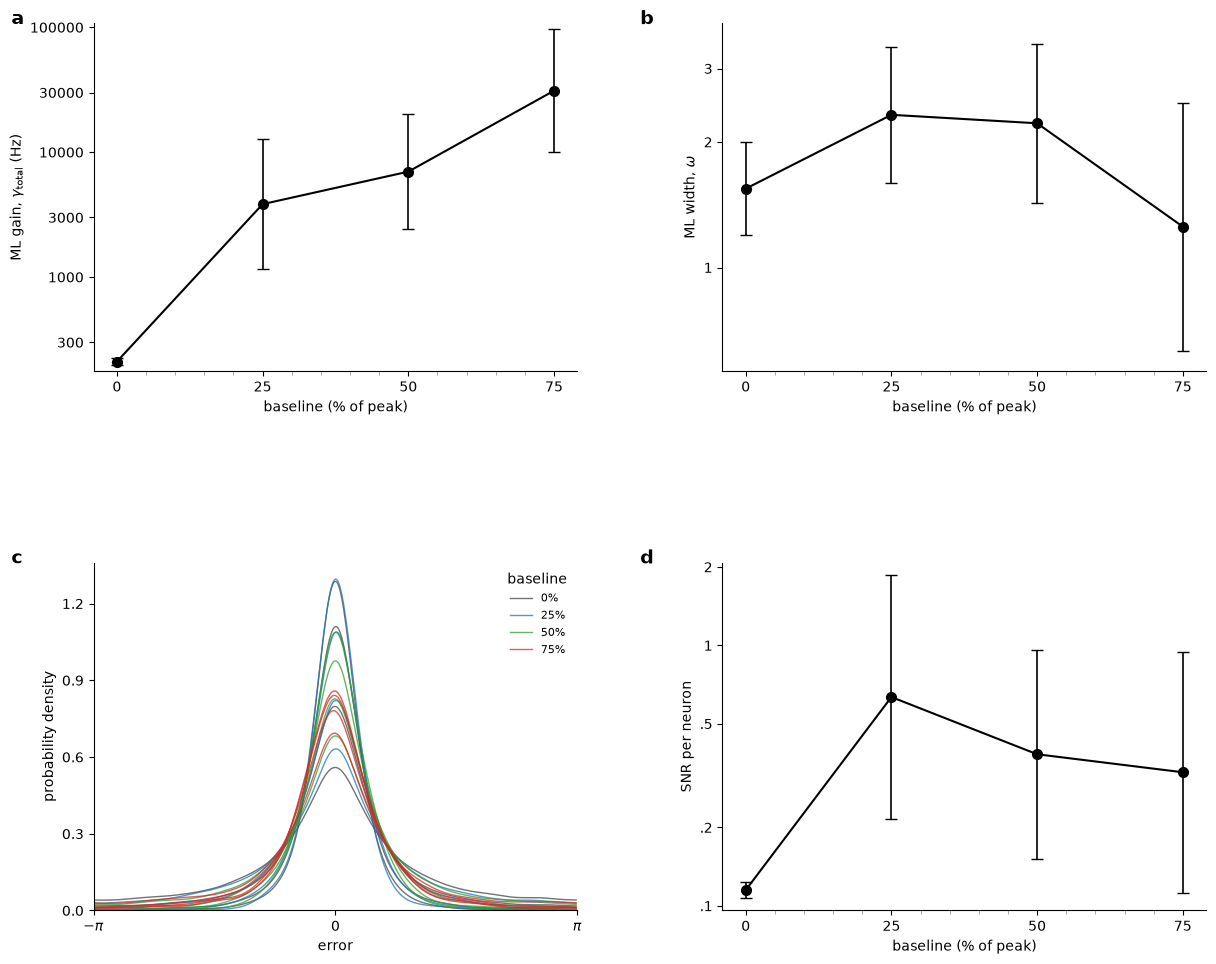

In [12]:
# === Figure: Experiment 5 (GP baseline identifiability), means over seeds ===
# Same design as the original figure; points are geometric means over seeds
# with 95% confidence intervals.
from scipy.special import i0
from matplotlib.ticker import FuncFormatter, FixedLocator, MaxNLocator

THESIS_FIG_DIR = Path(PROJECT_ROOT) / 'simulated_experiments' / 'thesis_figures' / 'experiment_5'
THESIS_STEM = 'fig_5' if DISTRIBUTION == 'gamma' else f'fig_5_{DISTRIBUTION}'

fig = plt.figure(figsize=(12.5, 10.5))
gs = gridspec.GridSpec(2, 2, hspace=0.55, wspace=0.30,
                       left=0.085, right=0.975, bottom=0.075, top=0.92)
ax_a = fig.add_subplot(gs[0, 0]); ax_b = fig.add_subplot(gs[0, 1])
ax_c = fig.add_subplot(gs[1, 0]); ax_d = fig.add_subplot(gs[1, 1])

x_pct = np.array([b * 100 for b in BASELINE_FRACS])
LINE_KW = dict(color='black', marker='o', ms=7, lw=1.5, zorder=3,
               capsize=4, elinewidth=1.2)


def _decimal_fmt(v, _pos):
    """Strip the leading zero from decimal tick labels (0.25 -> .25)."""
    if v <= 0:
        return ''
    s = ('%g' % v)
    return s[1:] if s.startswith('0.') else s


def _log_ticks(ylo, yhi):
    """Complete, uncrowded ticks: 1-2-5 per decade for wide ranges, linear-nice
    ticks for sub-decade ranges; never fewer than two labelled ticks."""
    dec = np.log10(yhi) - np.log10(ylo)
    if dec < 1.0:
        t = MaxNLocator(nbins=5, steps=[1, 2, 2.5, 5, 10], min_n_ticks=2).tick_values(ylo, yhi)
    else:
        mult = (1,) if dec >= 4 else (1, 3) if dec >= 2 else (1, 2, 5)
        kmin, kmax = int(np.floor(np.log10(ylo))), int(np.ceil(np.log10(yhi)))
        t = [m * 10.0**k for k in range(kmin, kmax + 1) for m in mult]
    t = np.asarray(t, float)
    t = t[(t >= ylo) & (t <= yhi)]
    return t if t.size >= 2 else np.array([ylo, yhi])


def style_log_y(ax, vals, pad=1.12):
    """Log y with limits hugging the data (means and error bars)."""
    ax.set_yscale('log')
    vals = np.asarray(vals, float); vals = vals[np.isfinite(vals) & (vals > 0)]
    ylo, yhi = vals.min() / pad, vals.max() * pad
    ax.set_ylim(ylo, yhi)
    ax.yaxis.set_major_locator(FixedLocator(_log_ticks(ylo, yhi)))
    ax.yaxis.set_major_formatter(FuncFormatter(_decimal_fmt))
    ax.minorticks_off()


def style_baseline_axis(ax, label):
    ax.set_xlabel('baseline (% of peak)')
    ax.set_xticks(x_pct)                                   # majors = sampled baselines (labelled)
    ax.set_xticklabels([f'{int(v)}' for v in x_pct])
    ax.set_xticks(np.arange(0, 81, 5), minor=True)         # minors every 5% (unlabelled)
    ax.set_xlim(x_pct.min() - 4, x_pct.max() + 4)
    ax.tick_params(axis='x', which='minor', length=3, color='#999999')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.text(-0.17, 1.04, label, transform=ax.transAxes,
            fontsize=14, fontweight='bold', va='top')


def _mean_ci(ax, data):
    """Geometric mean over seeds with its 95% CI."""
    m, lo, hi = geo_mean_ci(data)
    ax.errorbar(x_pct, m, yerr=np.vstack([m - lo, hi - m]), **LINE_KW)
    style_log_y(ax, np.concatenate([m, lo, hi]))


# ---- Panel a: gamma_total ----
_mean_ci(ax_a, GAIN)
ax_a.set_ylabel(r'ML gain, $\gamma_{\mathrm{total}}$ (Hz)')
style_baseline_axis(ax_a, r'$\mathbf{a}$')

# ---- Panel b: omega ----
_mean_ci(ax_b, OMEGA)
ax_b.set_ylabel(r'ML width, $\omega$')
style_baseline_axis(ax_b, r'$\mathbf{b}$')

# ---- Panel c: error distributions across set sizes, baselines overlaid (mean over seeds) ----
def _vm_kde(errors, eval_pts, kappa):
    d = eval_pts[:, None] - errors[None, :]
    log_w = kappa * np.cos(d)
    m = log_w.max(axis=1, keepdims=True)
    w = np.exp(log_w - m)
    return (w.mean(axis=1) * np.exp(m.squeeze())) / (2.0 * np.pi * i0(kappa))

PANEL_C_SET_SIZES = [N for N in (1, 2, 4, 8) if N in SET_SIZES]
_palette = ['#444444', '#1f77b4', '#2ca02c', '#d62728', '#9467bd', '#8c564b']
KAPPA_KDE_PANEL_C = 50.0
eval_pts = np.linspace(-np.pi, np.pi, 400, endpoint=False)

for j, bf in enumerate(BASELINE_FRACS):
    color = _palette[j % len(_palette)]
    for l in PANEL_C_SET_SIZES:
        density = np.mean([_vm_kde(seed_res[j]['fitted_errors'][l], eval_pts, KAPPA_KDE_PANEL_C)
                           for seed_res in results_by_seed], axis=0)
        ax_c.plot(eval_pts, density, color=color, lw=1.0, alpha=0.75,
                  label=f'{int(bf*100)}%' if l == PANEL_C_SET_SIZES[0] else None)

ax_c.set_xlim(-np.pi, np.pi)
ax_c.set_xticks([-np.pi, 0, np.pi])
ax_c.set_xticklabels([r'$-\pi$', '0', r'$\pi$'])
ax_c.set_ylim(bottom=0)
ax_c.yaxis.set_major_locator(MaxNLocator(nbins=5, min_n_ticks=2))
ax_c.set_xlabel('error')
ax_c.set_ylabel('probability density')
ax_c.legend(fontsize=8, frameon=False, loc='upper right', title='baseline')
ax_c.spines['top'].set_visible(False)
ax_c.spines['right'].set_visible(False)
ax_c.text(-0.17, 1.04, r'$\mathbf{c}$', transform=ax_c.transAxes,
          fontsize=14, fontweight='bold', va='top')

# ---- Panel d: SNR ----
_mean_ci(ax_d, SNR)
ax_d.set_ylabel('SNR per neuron')
style_baseline_axis(ax_d, r'$\mathbf{d}$')

saved = []
for folder, name in ((OUTPUT_DIR, f'experiment_5_baseline_identifiability_M{M}_{N_SEEDS}seeds'),
                     (THESIS_FIG_DIR, THESIS_STEM)):
    folder.mkdir(parents=True, exist_ok=True)
    for ext in ('png', 'pdf'):
        path = (folder / f'{name}.{ext}').resolve()
        fig.savefig(path, dpi=300, bbox_inches='tight')
        saved.append(path)
missing = [str(p) for p in saved if not p.exists()]
if missing:
    raise IOError(f'Figure not written: {missing}')
print('Saved:\n  ' + '\n  '.join(str(p) for p in saved))
print(f'  For the caption: panels a, b and d have log y-axes and a linear baseline axis; '
      f'panel c has linear axes. Points are geometric means over {N_SEEDS} population '
      f'seeds with 95% confidence intervals; panel c shows the mean density over seeds.')
plt.show()

In [13]:
# === Save results: per-baseline summary, tests and raw per-seed fits ===
summary_path = OUTPUT_DIR / 'exp5_summary_by_baseline.csv'
with open(summary_path, 'w', newline='') as fh:
    w = csv.writer(fh)
    w.writerow(['baseline_pct', 'n_seeds', 'gamma_total_geomean', 'gamma_ci_lo', 'gamma_ci_hi',
                'omega_geomean', 'omega_ci_lo', 'omega_ci_hi', f'{SIGMA_NAME}_mean',
                f'{SIGMA_NAME}_ci_lo', f'{SIGMA_NAME}_ci_hi', 'snr_geomean', 'snr_ci_lo',
                'snr_ci_hi', 'cost_mean', 'cost_ci_lo', 'cost_ci_hi', 'noise_floor'])
    for j, p in enumerate(pct):
        w.writerow([p, N_SEEDS, *(t[j] for t in g_ci), *(t[j] for t in w_ci),
                    *(t[j] for t in s_ci), *(t[j] for t in snr_ci), *(t[j] for t in c_ci),
                    NOISE_FLOOR])

tests_path = OUTPUT_DIR / 'exp5_tests_vs_baseline0.csv'
with open(tests_path, 'w', newline='') as fh:
    w = csv.writer(fh)
    w.writerow(['quantity', 'baseline_pct', 'ratio_geomean', 'ci_lo', 'ci_hi',
                'alternative', 'p_holm'])
    w.writerows(tests)

raw_path = OUTPUT_DIR / 'exp5_seed_results.pkl'
with open(raw_path, 'wb') as fh:
    pickle.dump({'config': _fit_config, 'N_SEEDS': N_SEEDS, 'SEED_BASES': SEED_BASES,
                 'noise_floor': NOISE_FLOOR, 'results_by_seed': results_by_seed}, fh)

print('Saved:')
for p in (summary_path, tests_path, raw_path):
    print(f'  {p}')

Saved:
  /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/bays_2014/result_data/experiment_5/20261020/sparse_sharp_100_gp_10seeds/210923/exp5_summary_by_baseline.csv
  /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/bays_2014/result_data/experiment_5/20261020/sparse_sharp_100_gp_10seeds/210923/exp5_tests_vs_baseline0.csv
  /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/bays_2014/result_data/experiment_5/20261020/sparse_sharp_100_gp_10seeds/210923/exp5_seed_results.pkl
